# Staggered Adoption — First Moves Above the Federal Minimum Wage and Food-Service Employment

**Artifact class:** `causal_analysis`  ·  **Data mode:** `empirical`  ·  **Vintage:** BLS QCEW, 2014 Q1 to 2023 Q4 (each quarter a separate file; the Bureau revises, so this is the retrieval, not a pinned vintage)

This notebook uses **real data only**. There is no synthetic generator and no fallback. If a
retrieval fails, a cell is withheld in a way the plan did not allow for, or a check stops, the
notebook stops.

The analysis was fixed in a **pre-analysis plan** (`pap/C03_pap.md`) committed before any table here
was retrieved. The notebook is bound to that file by its SHA-256 and says where it departs from it.

*Proprietary. SPDX-License-Identifier: LicenseRef-Proprietary*

## Learning Objectives

By the end of this notebook you will be able to:

1. **Explain** why a two-way fixed-effects regression with staggered treatment timing compares some
   units to others that are *already treated*, and what that does to the estimate.
2. **Decompose** a two-way fixed-effects estimate into its two-by-two comparisons and read the weights.
3. **Estimate** an effect with an interaction-weighted event-study estimator that never uses an
   already-treated unit as a control.
4. **Check** that estimator against a second one built on different controls (never-treated and
   not-yet-treated), and apply a decision rule written before the data were seen.
5. **Say, from computed numbers and not from prose,** whether the naive estimate and the robust one
   disagree in sign.

## Prerequisites

**Knowledge.** Two-way fixed effects; the difference-in-differences estimand (see C01); what a
cluster-robust standard error is for.

**Setup.** No API key is needed: the QCEW files are open. The retrieval makes 40 requests of about
0.8 MB each and takes several minutes; the Bureau sometimes answers HTTP 503 to a burst, and the
cell waits and retries only on that status.

**Packages.** `pandas`, `numpy`, `scipy`, `matplotlib`, and the local `krl_tutorials_data` package
(its `methods.did` module holds the estimators).

**Prior notebooks.** C01 introduces the identification contract and the two-by-two.

## Data Provenance

| Item | Source | Role |
|---|---|---|
| QCEW industry slice, NAICS 722, county level, private ownership | BLS Quarterly Census of Employment and Wages, one file per quarter | outcome: log of mean monthly employment |
| `data/policy/minimum_wage/state_schedule.csv` | U.S. Department of Labor, January-1 state minimum wages | treatment timing |

Each quarter's request is recorded in `provenance/`, bound to the plan's SHA-256. A QCEW cell is
**withheld** when publishing it could identify an employer, and the Bureau publishes the withheld
values as zeros; the client converts them to missing before any arithmetic. The Bureau serves its
slices from 2014 Q1, so the window is 2014–2023, not the track's 2012–2023; the plan records this.

**The check behind that statement.** On 2026-10-22, before the plan was committed, the industry-slice
endpoint for NAICS 722 was requested for 2012 Q1 (HTTP 503, which says nothing about availability),
2013 Q4 (HTTP 404), 2014 Q1 (HTTP 200) and 2023 Q4 (HTTP 503). A slice from 2014 on was therefore
requested. No value was read from any of them: the step that would have parsed the saved file failed
on the last response, an error page, and the file was deleted. A probe of the Bureau's county-area
endpoint read only status codes. So the 404 is established for 2013 Q4 of the industry slice, and the plan's
"earlier quarters" rests on that quarter and on the area endpoint.

## Design and identification

**Estimand.** The average effect, over the first twelve quarters after a state's minimum wage first
exceeds the federal minimum, on county private employment in food services and drinking places, in
log points, averaged over adopting cohorts.

**Assumption.** Parallel trends in the absence of the increase, between each adopting cohort and the
counties used as its control. With staggered timing the assumption has to hold for *every* comparison
the estimator makes, which is why the choice of comparison matters.

**Decision rule, fixed in the plan.** No effect if the 95% interval of the headline estimate contains
zero. Credible only if both falsifications pass; otherwise the estimates are descriptive.

In [1]:
"""Configuration. Every analytic choice is named here, not inferred."""
from __future__ import annotations

import hashlib
import io
import sys
import time as clock
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests
from scipy import stats

_here = Path.cwd().resolve()
for _cand in (_here, *_here.parents):
    if (_cand / "src" / "krl_tutorials_data").is_dir():
        sys.path.insert(0, str(_cand / "src"))
        REPO_ROOT = _cand
        break
else:
    raise SystemExit("Could not locate krl_tutorials_data from " + str(_here))

from krl_tutorials_data.methods import did
from krl_tutorials_data.provenance import DataProvenance
from krl_tutorials_data.sources import DataAccessError, UpstreamError, fetch_qcew

NB_DIR = REPO_ROOT / "projects" / "09-causal-identification" / "C03_minimum_wage_staggered"
PAP = NB_DIR / "pap" / "C03_pap.md"
PAP_SHA256 = hashlib.sha256(PAP.read_bytes()).hexdigest()

FIRST_YEAR, LAST_YEAR = 2014, 2023
QUARTERS = [(y, q) for y in range(FIRST_YEAR, LAST_YEAR + 1) for q in (1, 2, 3, 4)]
FEDERAL = 7.25
LEADS, POST_QUARTERS = 4, 12          # event window: -4 and earlier binned; headline = e 0..11
N_BOOT, SEED = 999, 20261022
TARGET = "lnemp"
ADDED = "not pre-specified (added after review, 2026-10-23)"
PANDEMIC = (4 * (2020 - FIRST_YEAR), 4 * (2021 - FIRST_YEAR) + 3)   # 2020 Q1 to 2021 Q4, as t

print(f"pre-analysis plan : {PAP.relative_to(REPO_ROOT)}")
print(f"plan SHA-256      : {PAP_SHA256}")
print(f"window            : {FIRST_YEAR}Q1-{LAST_YEAR}Q4, {len(QUARTERS)} quarters")
print(f"bootstrap         : {N_BOOT} draws, seed {SEED} (group-time estimator, falsification 2)")

pre-analysis plan : projects/09-causal-identification/C03_minimum_wage_staggered/pap/C03_pap.md
plan SHA-256      : 65be61d3db840e93d8dc6241defe80b10e772d40c2c2c4735e38d6c7d3831f22
window            : 2014Q1-2023Q4, 40 quarters
bootstrap         : 999 draws, seed 20261022 (group-time estimator, falsification 2)


### Retrieving the quarterly files

One request per quarter for NAICS 722 in every county. The cell waits and retries only on HTTP 503,
which the Bureau uses to slow a burst; any other failure stops the notebook.

In [2]:
def get_slice(year: int, quarter: int):
    """One quarter's industry slice, retrying only a 503 with a growing pause."""
    for pause in (0, 5, 15, 45, 90):
        clock.sleep(pause)
        try:
            return fetch_qcew(year=year, quarter=quarter, industry="722", contact="research")
        except UpstreamError as exc:
            if "HTTP 503" not in str(exc):
                raise
    raise UpstreamError(f"QCEW kept answering 503 for {year} Q{quarter}")


parts, records, withheld_rows = [], [], 0
try:
    for year, quarter in QUARTERS:
        frame, prov = get_slice(year, quarter)
        county = frame[(frame["own_code"] == "5") & (frame["agglvl_code"] == "75")].copy()
        county["year"], county["quarter"] = year, quarter
        parts.append(county[["area_fips", "year", "quarter", "month1_emplvl", "month2_emplvl",
                             "month3_emplvl", "suppressed"]])
        withheld_rows += int(county["suppressed"].sum())
        prov.with_pap(PAP).write(NB_DIR / "provenance" / f"c03_qcew_722_{year}q{quarter}.json")
        records.append(prov)
except DataAccessError as exc:
    print("HALTED - real data could not be obtained.")
    print(f"  failure class : {type(exc).__name__}")
    print(f"  detail        : {exc}")
    raise

raw = pd.concat(parts, ignore_index=True)
print(f"quarters retrieved : {len(records)}; county-quarter rows: {len(raw):,}")
print(f"withheld rows      : {withheld_rows:,} ({withheld_rows / len(raw):.1%})")
print(records[0].render())

quarters retrieved : 40; county-quarter rows: 130,072
withheld rows      : 24,723 (19.0%)
Source      : U.S. Bureau of Labor Statistics - QCEW industry 722, 2014 Q1
Vintage     : 2014Q1  (NOT pinned - the source serves no prior vintage; this retrieval is the only one)
Endpoint    : https://data.bls.gov/cew/data/api/2014/1/industry/722.csv
Retrieved   : 2026-10-23T20:18:11+00:00
Shape       : 4166 rows x 43 cols
Payload hash: 36e56d65049d7ef4...  (response-bytes)
Data mode   : EMPIRICAL
Variables   :
              qtrly_estabs     QCEW field
              month1_emplvl    QCEW field
              month2_emplvl    QCEW field
              month3_emplvl    QCEW field
              total_qtrly_wages QCEW field
              taxable_qtrly_wages QCEW field
              qtrly_contributions QCEW field
              avg_wkly_wage    QCEW field
Limitations :
              - 934 of 4166 rows carry disclosure_code 'N' (withheld to protect employer identity).
              - 6538 withheld values w

In [3]:
"""Classify every state from the DOL schedule, as the plan defines."""
schedule = pd.read_csv(REPO_ROOT / "data" / "policy" / "minimum_wage" / "state_schedule.csv")
TERRITORIES = {"Guam", "Puerto Rico", "U.S. Virgin Islands", "Virgin Islands"}
window = schedule[(schedule["year"] >= FIRST_YEAR) & (schedule["year"] <= LAST_YEAR)
                  & (schedule["jurisdiction"] != "Federal (FLSA)")
                  & (~schedule["jurisdiction"].isin(TERRITORIES))]
federal_rows = schedule[(schedule["jurisdiction"] == "Federal (FLSA)") & schedule["year"].between(FIRST_YEAR, LAST_YEAR)]
assert (federal_rows["rate_low"] == FEDERAL).all(), "the federal rate must be constant over the window"

first_above = {}
for state, rows in window.groupby("jurisdiction"):
    above = rows[rows["rate_low"].fillna(0) > FEDERAL]["year"]
    first_above[state] = int(above.min()) if len(above) else None

classes = pd.Series({s: ("treated throughout" if y == FIRST_YEAR else "never treated" if y is None else "adopter")
                     for s, y in first_above.items()})
print(classes.value_counts().to_string())
print("adopters by first year above federal:",
      sorted((y, sum(v == y for v in first_above.values())) for y in set(first_above.values()) if y and y > FIRST_YEAR))
assert len(first_above) == 51, "expected the 50 states and the District of Columbia"
# Tiered schedules (a lower and an upper rate): the plan's rule reads the lower one.
tier_rows = window[(window["rate_low"] <= FEDERAL) & (window["rate_high"] > FEDERAL)]
TIERED = sorted(tier_rows["jurisdiction"].unique())
first_high = {}
for state_, rows_ in window.groupby("jurisdiction"):
    above_ = rows_[rows_["rate_high"].fillna(0) > FEDERAL]["year"]
    first_high[state_] = int(above_.min()) if len(above_) else None
print("states whose upper tier is above the federal minimum while the lower tier is not, in some year:")
print(pd.DataFrame({"state": TIERED,
                    "first year above, lower tier (the plan's rule)": [first_above[x] for x in TIERED],
                    "first year above, upper tier": [first_high[x] for x in TIERED],
                    "years tiered": [", ".join(map(str, sorted(tier_rows[tier_rows["jurisdiction"] == x]["year"]))) for x in TIERED]}).to_string(index=False))

treated throughout    21
never treated         20
adopter               10
adopters by first year above federal: [(2015, 6), (2017, 2), (2020, 1), (2021, 1)]
states whose upper tier is above the federal minimum while the lower tier is not, in some year:
    state  first year above, lower tier (the plan's rule)  first year above, upper tier                       years tiered
Minnesota                                            2017                          2014                   2014, 2015, 2016
   Nevada                                            2020                          2014 2014, 2015, 2016, 2017, 2018, 2019
     Ohio                                            2017                          2014                   2014, 2015, 2016


In [4]:
"""State names for the two-digit codes, from the Census Bureau's own reference file."""
FIPS_URL = "https://www2.census.gov/geo/docs/reference/state.txt"
reply = requests.get(FIPS_URL, timeout=60, headers={"User-Agent": "telosyn-notebooks/1.0"})
reply.raise_for_status()
codes = pd.read_csv(io.StringIO(reply.text), sep="|", dtype=str)
state_name = dict(zip(codes["STATE"], codes["STATE_NAME"]))
DataProvenance.build(
    pinned=False, source_name="U.S. Census Bureau", dataset="State FIPS codes and names",
    vintage="retrieval", endpoint=FIPS_URL, variables={"STATE": "FIPS code", "STATE_NAME": "name"},
    payload=reply.content, row_count=len(codes), column_count=len(codes.columns),
    notes=("A reference list used only to attach state names to county codes.",),
).with_pap(PAP).write(NB_DIR / "provenance" / "c03_state_fips.json")
print(f"state codes read: {len(codes)}")

state codes read: 57


In [5]:
"""County panel: log mean monthly employment, balanced, with the coverage that costs."""
raw["area_fips"] = raw["area_fips"].astype(str).str.zfill(5)
raw["t"] = 4 * (raw["year"] - FIRST_YEAR) + (raw["quarter"] - 1)
raw["emp"] = raw[["month1_emplvl", "month2_emplvl", "month3_emplvl"]].mean(axis=1, skipna=False)
raw["state"] = raw["area_fips"].str[:2].map(state_name)
raw = raw[raw["state"].isin(first_above)].copy()
raw["usable"] = (~raw["suppressed"]) & (raw["emp"] > 0)

per_county = raw.groupby("area_fips")["usable"].sum()
keep = per_county[per_county == len(QUARTERS)].index
first_q = raw[raw["t"] == 0]
share_emp = first_q[first_q["area_fips"].isin(keep)]["emp"].sum() / first_q[first_q["usable"]]["emp"].sum()
print(f"counties with any row     : {per_county.size:,}")
print(f"counties usable in all {len(QUARTERS)} quarters: {keep.size:,} ({keep.size / per_county.size:.1%})")
print(f"their share of 2014 Q1 employment among counties with a disclosed value that quarter: {share_emp:.1%} "
      "(employment in withheld counties is not observed, so this is not a share of the state totals)")
print(f"counties kept: {keep.size / per_county.size:.1%} of those with any row; every average here is an unweighted county average")
dropped = per_county.index.difference(keep)
by_county = raw[raw["area_fips"].isin(dropped)].groupby("area_fips").agg(
    rows=("t", "size"), withheld=("suppressed", "sum"), nonpositive=("emp", lambda v: int((v <= 0).sum())))
reason = pd.Series(np.where(by_county["withheld"] > 0, "a withheld quarter",
                   np.where(by_county["nonpositive"] > 0, "a zero value and no withheld quarter", "quarters absent from the file")),
                   index=by_county.index).value_counts()
print("counties dropped, by the first reason found:")
print(reason.to_string())
statewide_unknown = [c for c in per_county.index if c[2:] == "999"]
print(f"statewide-unknown county codes (xx999) among counties with any row: {len(statewide_unknown)}; kept in the balanced panel: {sum(c in set(keep) for c in statewide_unknown)}")

panel = raw[raw["area_fips"].isin(keep)].sort_values(["area_fips", "t"]).reset_index(drop=True)
panel["lnemp"] = np.log(panel["emp"])
assert panel[TARGET].var() > 0, "the outcome must vary"
panel["class"] = panel["state"].map(classes)
cohort_q = {s: (np.nan if y is None else 0 if y == FIRST_YEAR else 4 * (y - FIRST_YEAR)) for s, y in first_above.items()}
panel["cohort"] = panel["state"].map(cohort_q)
panel["D"] = (panel["t"] >= panel["cohort"].fillna(np.inf)).astype(float)
by_class = panel.drop_duplicates("area_fips").groupby("class").agg(counties=("area_fips", "size"), states=("state", "nunique"))
print(by_class.to_string())

counties with any row     : 3,187
counties usable in all 40 quarters: 1,841 (57.8%)
their share of 2014 Q1 employment among counties with a disclosed value that quarter: 95.7% (employment in withheld counties is not observed, so this is not a share of the state totals)
counties kept: 57.8% of those with any row; every average here is an unweighted county average


counties dropped, by the first reason found:
a withheld quarter                      1343
quarters absent from the file              2
a zero value and no withheld quarter       1
statewide-unknown county codes (xx999) among counties with any row: 50; kept in the balanced panel: 16
                    counties  states
class                               
adopter                  337      10
never treated            929      20
treated throughout       575      21


In [6]:
"""Who is in each cohort, and which calendar quarters its first twelve event quarters cover."""
def quarter_label(tq: int) -> str:
    return f"{FIRST_YEAR + tq // 4} Q{tq % 4 + 1}"

adopt = panel[panel["class"] == "adopter"].drop_duplicates("area_fips")
cohort_table = []
for c_, grp in adopt.groupby("cohort"):
    first_, last_ = int(c_), int(c_) + POST_QUARTERS - 1
    cohort_table.append({
        "first quarter above": quarter_label(first_), "states": ", ".join(sorted(grp["state"].unique())),
        "counties": len(grp), "headline window": f"{quarter_label(first_)} to {quarter_label(min(last_, len(QUARTERS) - 1))}",
        "reference quarter": quarter_label(first_ - 1),
        "overlaps 2020 Q1-2021 Q4": bool(first_ <= PANDEMIC[1] and last_ >= PANDEMIC[0] or PANDEMIC[0] <= first_ - 1 <= PANDEMIC[1]),
    })
print(pd.DataFrame(cohort_table).to_string(index=False))
PANDEMIC_COHORTS = [float(c_) for c_, row_ in zip(sorted(adopt["cohort"].unique()), cohort_table) if row_["overlaps 2020 Q1-2021 Q4"]]
print(f"never-treated states: {panel[panel['class'] == 'never treated']['state'].nunique()}; treated-throughout states: {panel[panel['class'] == 'treated throughout']['state'].nunique()}")

first quarter above                                                            states  counties    headline window reference quarter  overlaps 2020 Q1-2021 Q4
            2015 Q1 Arkansas, Hawaii, Maryland, Nebraska, South Dakota, West Virginia       144 2015 Q1 to 2017 Q4           2014 Q4                     False
            2017 Q1                                                   Minnesota, Ohio       110 2017 Q1 to 2019 Q4           2016 Q4                     False
            2020 Q1                                                            Nevada        13 2020 Q1 to 2022 Q4           2019 Q4                      True
            2021 Q1                                                          Virginia        70 2021 Q1 to 2023 Q4           2020 Q4                      True
never-treated states: 20; treated-throughout states: 21


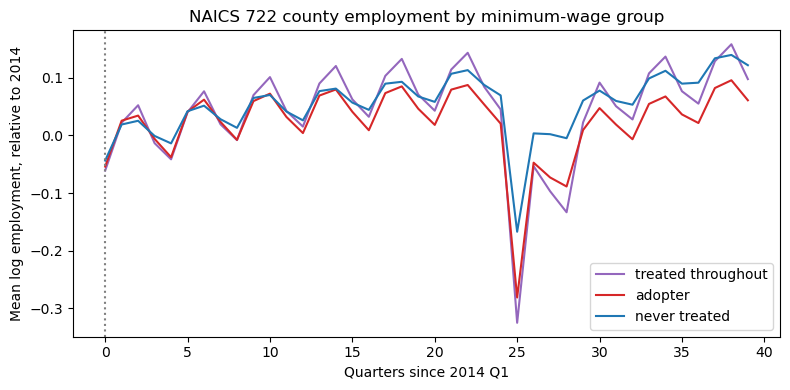

In [7]:
"""The raw picture: mean log employment by group, each relative to its 2014 average."""
means = panel.groupby(["t", "class"])["lnemp"].mean().unstack("class")
means = means - means.loc[0:3].mean()
fig, ax = plt.subplots(figsize=(8, 4))
for name, colour in (("treated throughout", "tab:purple"), ("adopter", "tab:red"), ("never treated", "tab:blue")):
    ax.plot(means.index, means[name], color=colour, label=name)
ax.axvline(0, color="grey", linestyle=":")
ax.set_xlabel("Quarters since 2014 Q1")
ax.set_ylabel("Mean log employment, relative to 2014")
ax.set_title("NAICS 722 county employment by minimum-wage group")
ax.legend()
plt.tight_layout()
plt.show()

### Estimate 1: the naive two-way fixed-effects regression

One treatment dummy, county and quarter fixed effects, all three groups in the sample. This is the
regression most people would run first.

In [8]:
"""Naive TWFE on the full balanced panel."""
y = panel["lnemp"].to_numpy()
unit, tq = panel["area_fips"].to_numpy(), panel["t"].to_numpy()
state = panel["state"].to_numpy()
naive = did.twfe(y, panel[["D"]].to_numpy(dtype=float), unit, tq, cluster=state)
b_naive, se_naive = float(naive.coef[0]), float(naive.se[0])
t_crit = float(stats.t.ppf(0.975, naive.n_clusters - 1))
print(f"counties / quarters / rows : {naive.n_units:,} / {naive.n_periods} / {naive.n_obs:,}")
print(f"naive TWFE estimate        : {b_naive:+.4f} log points (SE {se_naive:.4f}, {naive.n_clusters} state clusters)")
print(f"95% interval               : [{b_naive - t_crit * se_naive:+.4f}, {b_naive + t_crit * se_naive:+.4f}]")

counties / quarters / rows : 1,841 / 40 / 73,640
naive TWFE estimate        : -0.0250 log points (SE 0.0133, 51 state clusters)
95% interval               : [-0.0516, +0.0017]


### Estimate 2: what that regression is averaging

The Goodman-Bacon decomposition rebuilds the estimate above from every two-by-two comparison it
makes, with the weight each one carries. A comparison in which a *later*-treated group is compared
with an *earlier*-treated group that is already treated uses a treated unit as the control; those are
the comparisons that can pull the estimate the wrong way when effects change over time. Whether they do
here is read off the contributions printed below, not assumed.

decomposition rebuilds the naive estimate: -0.0250
number of two-by-two comparisons: 20
      comparison  weight  weighted mean estimate
treated vs never  0.5644                 -0.0334
earlier vs later  0.0239                 -0.0084
later vs earlier  0.4117                 -0.0143


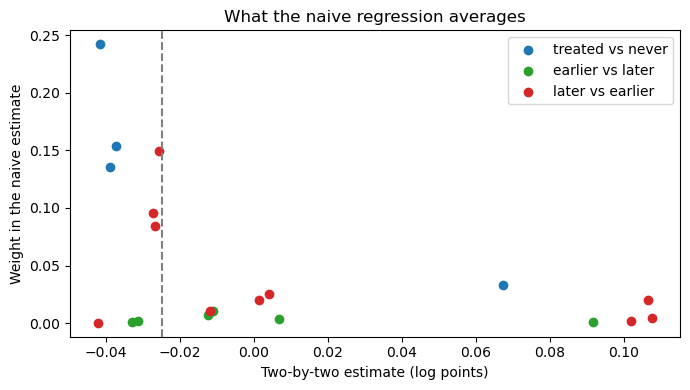

In [9]:
"""Decompose the naive estimate."""
dec = did.bacon_decomposition(y, unit, tq, panel["cohort"].to_numpy())
assert abs(dec.twfe - b_naive) < 1e-8
kinds = dec.by_kind()
table = pd.DataFrame(
    [{"comparison": k.replace("_", " "), "weight": w, "weighted mean estimate": m} for k, (w, m) in kinds.items()]
)
print(f"decomposition rebuilds the naive estimate: {dec.twfe:+.4f}")
print(f"number of two-by-two comparisons: {len(dec.comparisons)}")
print(table.round(4).to_string(index=False))

fig, ax = plt.subplots(figsize=(7, 4))
for kind, colour in (("treated_vs_never", "tab:blue"), ("earlier_vs_later", "tab:green"), ("later_vs_earlier", "tab:red")):
    pts = [(c.estimate, c.weight) for c in dec.comparisons if c.kind == kind]
    if pts:
        ax.scatter([p[0] for p in pts], [p[1] for p in pts], color=colour, label=kind.replace("_", " "))
ax.axvline(b_naive, color="grey", linestyle="--")
ax.set_xlabel("Two-by-two estimate (log points)")
ax.set_ylabel("Weight in the naive estimate")
ax.set_title("What the naive regression averages")
ax.legend()
plt.tight_layout()
plt.show()

### Estimate 3: an interaction-weighted event study that never uses a treated unit as a control

The treated-throughout states have no pre-period, so they are set aside here. Each adopting cohort is
compared with never-treated counties, event time by event time, and the cohort-specific effects are
averaged with weights equal to each cohort's share. The headline is the mean effect over the first
twelve quarters.

cohorts (first treated quarter): [4, 12, 24, 28]; states clustered: 30
headline, mean ATT over event times 0-11: -0.0000 (SE 0.0052), 95% interval [-0.0107, +0.0106]


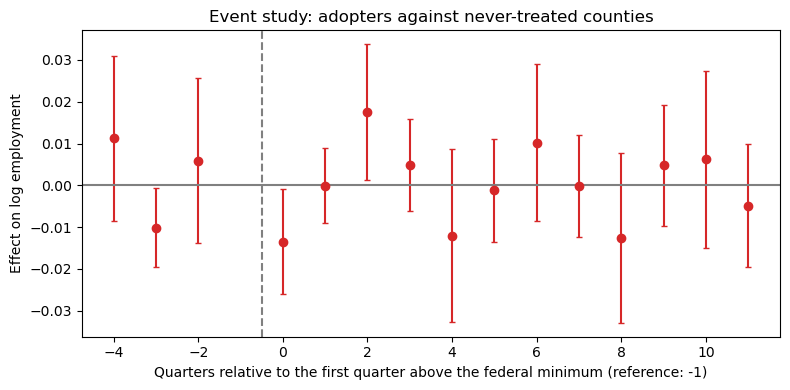

In [10]:
"""Sun-Abraham interaction-weighted estimator on adopters and never-treated counties."""
sub = panel[panel["class"] != "treated throughout"]
sa = did.sun_abraham(
    sub["lnemp"].to_numpy(), sub["area_fips"].to_numpy(), sub["t"].to_numpy(),
    sub["cohort"].to_numpy(), leads=LEADS, lags=int(sub["t"].max()), cluster=sub["state"].to_numpy(),
)
ev = np.array(sa.event_times)
post_mask = (ev >= 0) & (ev < POST_QUARTERS)
w_head = post_mask / post_mask.sum()
b_sa = float(w_head @ sa.att)
se_sa = float(np.sqrt(w_head @ sa.vcov @ w_head))
t_sa = float(stats.t.ppf(0.975, sa.n_clusters - 1))
ci_sa = (b_sa - t_sa * se_sa, b_sa + t_sa * se_sa)
print(f"cohorts (first treated quarter): {[int(c) for c in sa.cohorts]}; states clustered: {sa.n_clusters}")
print(f"headline, mean ATT over event times 0-{POST_QUARTERS - 1}: {b_sa:+.4f} (SE {se_sa:.4f}), 95% interval [{ci_sa[0]:+.4f}, {ci_sa[1]:+.4f}]")

shown = (ev >= -LEADS) & (ev < POST_QUARTERS)
half = t_sa * sa.se
fig, ax = plt.subplots(figsize=(8, 4))
ax.errorbar(ev[shown], sa.att[shown], yerr=half[shown], fmt="o", color="tab:red", capsize=2)
ax.axhline(0, color="grey")
ax.axvline(-0.5, color="grey", linestyle="--")
ax.set_xlabel("Quarters relative to the first quarter above the federal minimum (reference: -1)")
ax.set_ylabel("Effect on log employment")
ax.set_title("Event study: adopters against never-treated counties")
plt.tight_layout()
plt.show()

In [11]:
"""Falsification 1: the pre-period coefficients are jointly zero."""
pre_idx = [list(ev).index(e) for e in (-4, -3, -2)]
b_pre = sa.att[pre_idx]
v_pre = sa.vcov[np.ix_(pre_idx, pre_idx)]
wald = float(b_pre @ np.linalg.solve(v_pre, b_pre))
f_pre = wald / len(pre_idx)
p_pre = float(stats.f.sf(f_pre, len(pre_idx), sa.n_clusters - 1))
PRE_PASS = p_pre >= 0.10
print(f"FALSIFICATION: pre-period event-time coefficients -4..-2 jointly zero | statistic={f_pre:.3f} | F({len(pre_idx)},{sa.n_clusters - 1}) p={p_pre:.4f}, threshold 0.10 | verdict={'PASS' if PRE_PASS else 'FAIL'}")

FALSIFICATION: pre-period event-time coefficients -4..-2 jointly zero | statistic=4.354 | F(3,29) p=0.0119, threshold 0.10 | verdict=FAIL


In [12]:
"""What the pre-period test is looking at."""
leads_table = pd.DataFrame({"event time": [-4, -3, -2], "coefficient": b_pre, "se": sa.se[pre_idx]})
leads_table["t"] = leads_table["coefficient"] / leads_table["se"]
print(leads_table.round(4).to_string(index=False))
largest = leads_table.loc[leads_table["t"].abs().idxmax()]
print(f"Largest lead: event time {int(largest['event time'])}, {largest['coefficient']:+.4f} log points (t = {largest['t']:+.2f}).")
print(f"Headline effect for comparison: {b_sa:+.4f} log points. A lead of that size before adoption "
      f"{'is larger than' if abs(largest['coefficient']) > abs(b_sa) else 'is smaller than'} the headline effect.")

 event time  coefficient     se       t
         -4       0.0112 0.0097  1.1582
         -3      -0.0101 0.0047 -2.1627
         -2       0.0059 0.0097  0.6125
Largest lead: event time -3, -0.0101 log points (t = -2.16).
Headline effect for comparison: -0.0000 log points. A lead of that size before adoption is larger than the headline effect.


In [13]:
"""not pre-specified (added after review, 2026-10-23): the bin weights behind falsification 1."""
print(ADDED)
def sa_run(frame, bin_weights="units"):
    """Sun-Abraham headline (event times 0-11), its interval and the plan's pre-period test, on any sample."""
    fit_ = did.sun_abraham(
        frame[TARGET].to_numpy(), frame["area_fips"].to_numpy(), frame["t"].to_numpy(), frame["cohort"].to_numpy(),
        leads=LEADS, lags=int(frame["t"].max()), cluster=frame["state"].to_numpy(), bin_weights=bin_weights)
    ev_ = np.array(fit_.event_times)
    pm_ = (ev_ >= 0) & (ev_ < POST_QUARTERS)
    wv_ = pm_ / pm_.sum()
    b_ = float(wv_ @ fit_.att)
    se_ = float(np.sqrt(wv_ @ fit_.vcov @ wv_))
    tc_ = float(stats.t.ppf(0.975, fit_.n_clusters - 1))
    out = {"fit": fit_, "ev": ev_, "b": b_, "se": se_, "ci": (b_ - tc_ * se_, b_ + tc_ * se_), "f": np.nan, "p": np.nan}
    ix_ = [list(ev_).index(e) for e in (-4, -3, -2) if e in ev_]
    if len(ix_) == 3 and fit_.n_clusters - 1 >= 3:
        bb_, vv_ = fit_.att[ix_], fit_.vcov[np.ix_(ix_, ix_)]
        try:
            out["f"] = float(bb_ @ np.linalg.solve(vv_, bb_)) / 3
            out["p"] = float(stats.f.sf(out["f"], 3, fit_.n_clusters - 1))
        except np.linalg.LinAlgError:
            pass
    return out

units_run, obs_run = sa_run(sub, "units"), sa_run(sub, "observations")
assert abs(units_run["b"] - b_sa) < 1e-12 and abs(units_run["f"] - f_pre) < 1e-9, "the helper must reproduce the plan's cell"
verdict = lambda p_: "PASS" if p_ >= 0.10 else "FAIL"
print(f"pooled lead bin (event times <= -4) weighted by units (used above): F = {units_run['f']:.3f}, p = {units_run['p']:.4f}, verdict {verdict(units_run['p'])}")
print(f"pooled lead bin weighted by observations (the first run's weighting): F = {obs_run['f']:.3f}, p = {obs_run['p']:.4f}, verdict {verdict(obs_run['p'])}")
print(f"the verdict {'is' if verdict(units_run['p']) == verdict(obs_run['p']) else 'is NOT'} the same under both weightings; "
      f"the headline is {units_run['b']:+.4f} under unit weights and {obs_run['b']:+.4f} under observation weights.")

not pre-specified (added after review, 2026-10-23)


pooled lead bin (event times <= -4) weighted by units (used above): F = 4.354, p = 0.0119, verdict FAIL
pooled lead bin weighted by observations (the first run's weighting): F = 5.489, p = 0.0041, verdict FAIL
the verdict is the same under both weightings; the headline is -0.0000 under unit weights and -0.0000 under observation weights.


In [14]:
"""Falsification 2: never-treated and not-yet-treated controls give the same answer."""
cs = {}
for control in ("never", "not_yet"):
    cs[control] = did.group_time_att(
        sub["lnemp"].to_numpy(), sub["area_fips"].to_numpy(), sub["t"].to_numpy(), sub["cohort"].to_numpy(),
        leads=LEADS, lags=POST_QUARTERS - 1, control=control, n_boot=N_BOOT, seed=SEED,
        cluster=sub["state"].to_numpy(),
    )
    fit = cs[control]
    print(f"{control:8s} controls: overall ATT {fit.overall:+.4f}, bootstrap SE {fit.overall_se:.4f}, 95% interval [{fit.overall_ci[0]:+.4f}, {fit.overall_ci[1]:+.4f}]")
gap = cs["never"].overall - cs["not_yet"].overall
slack = max(cs["never"].overall_se, cs["not_yet"].overall_se)
AGREE_PASS = abs(gap) <= slack
print(f"FALSIFICATION: never-treated versus not-yet-treated controls | statistic={gap:.4f} | difference in overall ATT, larger bootstrap SE {slack:.4f} | verdict={'PASS' if AGREE_PASS else 'FAIL'}")

never    controls: overall ATT -0.0002, bootstrap SE 0.0075, 95% interval [-0.0151, +0.0133]


not_yet  controls: overall ATT +0.0001, bootstrap SE 0.0075, 95% interval [-0.0151, +0.0131]
FALSIFICATION: never-treated versus not-yet-treated controls | statistic=-0.0003 | difference in overall ATT, larger bootstrap SE 0.0075 | verdict=PASS


In [15]:
"""The estimates side by side, the decomposition's contributions, and the statements computed from them."""
pct = lambda v: 100.0 * (np.exp(v) - 1.0)
side = pd.DataFrame([
    {"estimate": "naive TWFE (all groups)", "log points": b_naive, "se": se_naive,
     "lo": b_naive - t_crit * se_naive, "hi": b_naive + t_crit * se_naive},
    {"estimate": "Sun-Abraham, never-treated controls", "log points": b_sa, "se": se_sa, "lo": ci_sa[0], "hi": ci_sa[1]},
    {"estimate": "group-time, never-treated controls", "log points": cs["never"].overall, "se": cs["never"].overall_se,
     "lo": cs["never"].overall_ci[0], "hi": cs["never"].overall_ci[1]},
    {"estimate": "group-time, not-yet-treated controls", "log points": cs["not_yet"].overall, "se": cs["not_yet"].overall_se,
     "lo": cs["not_yet"].overall_ci[0], "hi": cs["not_yet"].overall_ci[1]},
])
print(side.round(4).to_string(index=False))
print()
contrib = pd.DataFrame([{"comparison": k.replace("_", " "), "weight": w, "mean estimate": m, "weight x estimate": w * m}
                        for k, (w, m) in kinds.items()])
print(contrib.round(4).to_string(index=False))
print(f"the contributions sum to the naive estimate: {contrib['weight x estimate'].sum():+.4f} (naive {b_naive:+.4f})")
w_fb, m_fb = kinds["later_vs_earlier"]
w_nv, m_nv = kinds["treated_vs_never"]
print(f"Weight on comparisons that use an already-treated group as the control: {w_fb:.1%} (their mean estimate {m_fb:+.4f}).")
print(f"Treated-versus-never comparisons carry {w_nv:.1%} of the weight with a mean estimate of {m_nv:+.4f}; "
      f"already-treated controls carry {w_fb:.1%} with {m_fb:+.4f}. "
      f"Both are negative, so the already-treated comparisons {'do not' if np.sign(m_fb) == np.sign(m_nv) else 'do'} reverse the sign of the naive estimate.")
print(f"The naive regression pools every post-adoption quarter, to event time {int(max(ev))} for the earliest cohort, "
      f"including 2020-2023; the headline averages event times 0-{POST_QUARTERS - 1}. "
      f"The interaction-weighted mean over all available post-adoption quarters is {sa.overall:+.4f} (SE {sa.overall_se:.4f}), "
      f"against {b_sa:+.4f} for the headline window and {b_naive:+.4f} naive.")
differ = np.sign(b_naive) != np.sign(b_sa)
if abs(b_sa) < se_sa:
    print(f"The interaction-weighted estimate ({b_sa:+.4f}) is smaller than its standard error ({se_sa:.4f}); it is about zero, "
          "so whether it shares a sign with the naive estimate says nothing.")
else:
    print(f"The naive and the interaction-weighted estimates have {'opposite' if differ else 'the same'} sign "
          f"({b_naive:+.4f} against {b_sa:+.4f}).")
inside = ci_sa[0] <= b_naive <= ci_sa[1]
print(f"The naive estimate lies {'inside' if inside else 'outside'} the 95% interval of the interaction-weighted one.")
null = ci_sa[0] <= 0.0 <= ci_sa[1]
print(f"The headline interval {'contains' if null else 'excludes'} zero: the estimate is "
      f"{'not distinguishable from zero' if null else 'distinguishable from zero'}; in employment terms "
      f"{pct(b_sa):+.2f}% with 95% interval [{pct(ci_sa[0]):+.2f}%, {pct(ci_sa[1]):+.2f}%].")
print(f"Pre-period test passed: {PRE_PASS}; control-group agreement passed: {AGREE_PASS}.")
print("Both falsifications pass: by the plan's rule the estimates are credible for adopters 2015-2023."
      if PRE_PASS and AGREE_PASS else
      "At least one falsification fails: by the plan's rule the estimates are descriptive, not identified effects.")
lead_row = leads_table.loc[leads_table["event time"] == -4].iloc[0]
half = t_sa * se_sa
print(f"The lead at event time -4 is {lead_row['coefficient']:+.4f} log points ({pct(lead_row['coefficient']):+.2f}%), "
      f"{abs(lead_row['coefficient']) / half:.1f} times the half-width of the headline interval ({half:.4f}, or about {pct(half):.2f}%).")
if not PRE_PASS:
    print("Parallel trends is rejected by the plan's own test, so the interval above is not evidence that the effect is zero: "
          "an interval that contains zero is silent about an effect when the comparison it rests on fails its check.")

                            estimate  log points     se      lo     hi
             naive TWFE (all groups)     -0.0250 0.0133 -0.0516 0.0017
 Sun-Abraham, never-treated controls     -0.0000 0.0052 -0.0107 0.0106
  group-time, never-treated controls     -0.0002 0.0075 -0.0151 0.0133
group-time, not-yet-treated controls      0.0001 0.0075 -0.0151 0.0131

      comparison  weight  mean estimate  weight x estimate
treated vs never  0.5644        -0.0334            -0.0189
earlier vs later  0.0239        -0.0084            -0.0002
later vs earlier  0.4117        -0.0143            -0.0059
the contributions sum to the naive estimate: -0.0250 (naive -0.0250)
Weight on comparisons that use an already-treated group as the control: 41.2% (their mean estimate -0.0143).
Treated-versus-never comparisons carry 56.4% of the weight with a mean estimate of -0.0334; already-treated controls carry 41.2% with -0.0143. Both are negative, so the already-treated comparisons do not reverse the sign of the na

## Added after review (2026-10-23)

Everything from here to the Limitations is **not pre-specified (added after review, 2026-10-23)**. The
plan's primary result is the one above; none of these analyses replaces it. They answer questions the
review raised about the comparison, the sample and the inference.

In [16]:
"""not pre-specified (added after review, 2026-10-23): each adopting cohort's own leads, against never-treated counties."""
print(ADDED)
rows_ = []
for c_ in sorted(sub.loc[sub["cohort"].notna(), "cohort"].unique()):
    one_ = sub[(sub["cohort"] == c_) | sub["cohort"].isna()]
    r_ = sa_run(one_)
    states_ = ", ".join(sorted(sub[sub["cohort"] == c_]["state"].unique()))
    row_ = {"cohort": quarter_label(int(c_)), "states": states_}
    for e_ in (-4, -3, -2):
        i_ = list(r_["ev"]).index(e_)
        row_[f"lead {e_}"] = f"{r_['fit'].att[i_]:+.4f} ({r_['fit'].se[i_]:.4f})"
    rows_.append(row_)
print(pd.DataFrame(rows_).to_string(index=False))
print("coefficient (standard error) in log points; the event-time -4 cell pools every earlier quarter, so a cohort with a long pre-period contributes a long run of quarters to it.")

not pre-specified (added after review, 2026-10-23)


 cohort                                                            states          lead -4          lead -3          lead -2
2015 Q1 Arkansas, Hawaii, Maryland, Nebraska, South Dakota, West Virginia -0.0153 (0.0168) +0.0084 (0.0074) +0.0098 (0.0135)
2017 Q1                                                   Minnesota, Ohio +0.0151 (0.0158) +0.0130 (0.0094) +0.0208 (0.0202)
2020 Q1                                                            Nevada -0.0215 (0.0087) -0.0056 (0.0034) -0.0144 (0.0062)
2021 Q1                                                          Virginia +0.0646 (0.0168) -0.0814 (0.0153) -0.0166 (0.0099)
coefficient (standard error) in log points; the event-time -4 cell pools every earlier quarter, so a cohort with a long pre-period contributes a long run of quarters to it.


In [17]:
"""not pre-specified (added after review, 2026-10-23): the headline under other samples. None of these replaces the plan's result."""
print(ADDED)
tiered_set, pandemic_cohorts = set(TIERED), set(PANDEMIC_COHORTS)
no_tier = sub[~sub["state"].isin(tiered_set)]
no_pandemic = sub[~sub["cohort"].isin(pandemic_cohorts)]
neither = no_tier[~no_tier["cohort"].isin(pandemic_cohorts)]
no_ss999 = sub[sub["area_fips"].str[2:] != "999"]
specs = [("plan's sample (primary)", sub), (f"without tiered-schedule states ({', '.join(TIERED)})", no_tier),
         ("without the cohorts whose window overlaps 2020 Q1-2021 Q4", no_pandemic), ("without both", neither),
         ("without statewide-unknown county codes", no_ss999)]
sens_rows = []
for label_, frame_ in specs:
    try:
        r_ = sa_run(frame_)
    except ValueError as exc:
        sens_rows.append({"sample": label_, "adopting states": frame_[frame_["cohort"].notna()]["state"].nunique(), "note": f"not estimable: {exc}"})
        continue
    sens_rows.append({"sample": label_, "adopting states": frame_[frame_["cohort"].notna()]["state"].nunique(),
                      "headline": r_["b"], "lo": r_["ci"][0], "hi": r_["ci"][1], "% change": pct(r_["b"]),
                      "% lo": pct(r_["ci"][0]), "% hi": pct(r_["ci"][1]), "pre-test F": r_["f"], "p": r_["p"]})
print(pd.DataFrame(sens_rows).round(4).to_string(index=False))
print("log points unless marked %. With fewer than four states in the sample the pre-period test has no degrees of freedom and is shown as NaN; "
      "a cohort of one state gives a standard error that rests on a single treated cluster.")

not pre-specified (added after review, 2026-10-23)


                                                   sample  adopting states  headline      lo     hi  % change    % lo   % hi  pre-test F      p
                                  plan's sample (primary)               10   -0.0000 -0.0107 0.0106   -0.0049 -1.0649 1.0665      4.3544 0.0119
 without tiered-schedule states (Minnesota, Nevada, Ohio)                7   -0.0009 -0.0160 0.0141   -0.0927 -1.5857 1.4230      4.8395 0.0083
without the cohorts whose window overlaps 2020 Q1-2021 Q4                8   -0.0074 -0.0214 0.0066   -0.7395 -2.1212 0.6618      2.6312 0.0704
                                             without both                6   -0.0097 -0.0314 0.0121   -0.9616 -3.0918 1.2154      3.8296 0.0220
                   without statewide-unknown county codes               10    0.0007 -0.0095 0.0110    0.0734 -0.9437 1.1010      4.4035 0.0114
log points unless marked %. With fewer than four states in the sample the pre-period test has no degrees of freedom and is shown as NaN;

In [18]:
"""not pre-specified (added after review, 2026-10-23): the clustered standard error against a wild cluster bootstrap with Webb weights."""
print(ADDED)
N_WILD = 9999
win = sub[sub["cohort"].isna() | (sub["t"] - sub["cohort"] < POST_QUARTERS)].copy()
win["D_window"] = (win["t"] >= win["cohort"].fillna(np.inf)).astype(float)
args_ = (win[TARGET].to_numpy(), win[["D_window"]].to_numpy(), win["area_fips"].to_numpy(), win["t"].to_numpy())
tw_ = did.twfe(*args_, cluster=win["state"].to_numpy())
wb_ = did.wild_cluster_bootstrap(*args_, test_column=0, n_boot=N_WILD, seed=SEED, cluster=win["state"].to_numpy(), weights="webb")
p_analytic = float(2 * stats.t.sf(abs(tw_.coef[0] / tw_.se[0]), tw_.n_clusters - 1))
print(f"regression: log employment on one post-adoption indicator (event times 0-{POST_QUARTERS - 1}), adopters and never-treated counties, "
      f"county and quarter effects, {tw_.n_clusters} state clusters, {N_WILD} Webb-weight draws, seed {SEED}")
print(f"coefficient {tw_.coef[0]:+.4f} (clustered SE {tw_.se[0]:.4f}); t = {wb_.t_stat:+.3f}")
print(f"p-value: analytic (t, {tw_.n_clusters - 1} d.f.) {p_analytic:.4f}; wild cluster bootstrap-t {wb_.p_value:.4f}")
print(f"the clustered analytic standard error of the interaction-weighted headline is {se_sa:.4f}; the group-time bootstrap standard error is {cs['never'].overall_se:.4f}")
print("this regression still compares adopters with one another, so its coefficient is not the headline; it is shown only to compare the two ways of computing the p-value.")

not pre-specified (added after review, 2026-10-23)


regression: log employment on one post-adoption indicator (event times 0-11), adopters and never-treated counties, county and quarter effects, 30 state clusters, 9999 Webb-weight draws, seed 20261022
coefficient -0.0172 (clustered SE 0.0124); t = -1.387
p-value: analytic (t, 29 d.f.) 0.1761; wild cluster bootstrap-t 0.2940
the clustered analytic standard error of the interaction-weighted headline is 0.0052; the group-time bootstrap standard error is 0.0075
this regression still compares adopters with one another, so its coefficient is not the headline; it is shown only to compare the two ways of computing the p-value.


## Limitations

- **Suppressed county cells.** The balanced-panel rule drops every county with a withheld or zero cell in
  any quarter, and withholding is not random: it is applied where few establishments make a cell
  identifying. The panel cell prints how many counties are kept, why the rest were dropped, and the share of
  first-quarter employment in disclosed counties that the kept counties hold. That is not a share of the
  state totals, because employment in withheld counties is not observed. Every average here is an
  unweighted county average, and the small rural counties that are most often withheld are the ones
  missing; the estimates speak to the counties that remain. The retrieval also returns statewide-unknown
  codes (ending 999) that are not counties; the panel cell prints how many sit in the balanced panel, and a
  labelled sensitivity drops them.
- **Window.** The BLS slice API starts in 2014 Q1, so no state has a pre-period before 2014 and the
  states already above the federal minimum in 2014 have none at all. They are in the naive regression and
  its decomposition and absent from the interaction-weighted estimate, which therefore speaks only to
  adopters from 2015 to 2023.
- **Dating.** The schedule records January-1 values, so an increase made part-way through a year is dated
  to the next 1 January, and the file is not a consistent January-1 snapshot: some rows carry a rate that
  took effect part-way through the year. The errors run in both directions. As recalled and not verified in this
  build, Virginia's 2021 increase took effect on 1 May 2021 and is coded to 2021 Q1, a quarter early;
  Delaware's 2014 increase took effect in June 2014 and Delaware is coded as above the federal minimum
  for the whole of 2014, which makes it a treated-throughout state; and the rows for Maryland (2015, 2016, 2018) and
  California (2014) may show mid-year rates. The pre-period coefficients are the place where dating
  error would show.
- **Tiered schedules.** The plan reads the schedule's lower rate. For the states printed in the tiered-schedule table
  (Minnesota, Nevada and Ohio) the upper tier was above the federal minimum before the lower tier was,
  so the plan dates their first move later than the policy's first move above the federal minimum, which is
  what the estimand describes. Minnesota and Ohio form one adopting cohort and Nevada another. This
  follows the plan's literal rule and was not disclosed in the first run. The sensitivity
  without these states is labelled and does not replace the plan's result.
- **The pandemic.** The cohort table marks the cohorts whose headline window or reference quarter falls in
  2020-2021: Nevada's window starts in 2020 and Virginia's in 2021, with Virginia's reference quarter in
  2020 Q4. Their estimates are not separable from the pandemic's uneven effect on food service. The sensitivity
  without those cohorts is labelled and does not replace the plan's result.
- **Few treated clusters.** The cohort table shows how few states adopt in each year; two cohorts are single states.
  The analytic standard error, the group-time bootstrap standard error and the wild cluster bootstrap p-value
  are printed side by side, and they differ. With this few treated clusters none of them should be read to
  the second decimal.
- **Parallel trends is rejected.** The plan's pre-period test fails, which makes the estimates descriptive by the plan's
  own rule. The headline interval is reported as not distinguishable from zero, and that statement
  is not evidence of no effect. The cell after the side-by-side table compares the lead at event time -4 with the
  interval's half-width, and the cohort-by-cohort leads show where the violation sits. Bounds that let the
  pre-period violation carry forward (Rambachan and Roth, 2023) were not computed here.
- **Binary treatment.** Any move above the federal minimum counts the same, whatever its size, and later
  increases within a treated state are not modelled.
- **Spillovers.** Counties near a state border may respond to a neighbouring state's wage floor; the control
  group can contain such counties.
- **Departures from the pre-analysis plan.** The plan was not edited. The first run departed from it in four
  ways: the bootstrap seed that section 5 says is printed was not printed (it is now); the coverage share is
  computed over counties with a disclosed value, not over the retained states' employment, which the file does
  not contain; dropped counties were not split by reason (the panel cell now splits them); and the first run
  stated that it had not departed from the plan. After review, the library's Sun-Abraham estimator was corrected
  so that the pooled lead cell weights cohorts by their units and not by their observations. The plan does not specify the
  weighting; falsification 1 now uses unit weights, and the cell after it prints the statistic and verdict under both
  weightings. The plan's primary result is the one the plan defines. Everything labelled "not pre-specified" was
  added after review on 2026-10-23, and none of it replaces a result the plan defines.

## Key Takeaways

1. A two-way fixed-effects regression with staggered timing silently averages many comparisons, some of
   which use a treated group as the control. The decomposition makes the weights visible.
2. Whether that explains a gap between estimates is a computed statement, not an assumption: the side-by-side
   cell prints each kind of comparison's weight and contribution and the horizon each estimate averages
   over, and the gap is read from those.
3. A second estimator with different controls is a falsification, not a decoration: if never-treated and
   not-yet-treated controls disagree, one of the parallel-trends assumptions is wrong.
4. Fixing the sample rule, window and decision rule in a plan before retrieval is what lets a failed test
   be reported as a finding. Here the pre-period test is reported with its result; when it fails, the
   headline is descriptive, and an interval that contains zero is not evidence of no effect.
5. How a pooled cell is weighted, and which schedule rate dates a treatment, are analytic choices that move
   the lead coefficients; the labelled sensitivities show how far.

## Exercises

1. Re-run the interaction-weighted estimator with the headline window set to event times 0 to 3 and 0 to 19.
   How much of the answer is the first cohort?
2. Drop each adopting state in turn and recompute the headline. Which state moves it most?
3. Keep the treated-throughout states and use them as controls for the adopters. Which bucket of the
   decomposition does that add, and does the estimate move toward the naive one?
4. The plan dates treatment to the next 1 January. Shift every adopter's treatment two quarters earlier and
   look at the pre-period coefficients. What does that say about the dating error?

## References

Author, year and venue as recalled; **not verified against the published record in this build**.

- Goodman-Bacon (2021), *Difference-in-Differences with Variation in Treatment Timing*, Journal of Econometrics.
- Sun and Abraham (2021), *Estimating Dynamic Treatment Effects in Event Studies with Heterogeneous Treatment
  Effects*, Journal of Econometrics.
- Callaway and Sant'Anna (2021), *Difference-in-Differences with Multiple Time Periods*, Journal of Econometrics.
- Rambachan and Roth (2023), *A More Credible Approach to Parallel Trends*, Review of Economic Studies.
- Webb (2014), *Reworking Wild Bootstrap Based Inference for Clustered Errors*, Queen's Economics Department working paper.
- U.S. Bureau of Labor Statistics, Quarterly Census of Employment and Wages, open data access documentation.
- U.S. Department of Labor, Wage and Hour Division, state minimum wage history (see `data/policy/minimum_wage/SOURCES.md`).